# Part 1: Tumour patch classifier (PatchCamelyon)

**Goal:** teach a CNN to look at a small square of lymph-node tissue (96 × 96 pixels at 10× magnification) and say whether there is cancer (metastasis) in its centre.

**Why this comes first:** a whole slide is far too big for a model. In Part 2 we cut the slide into thousands of small squares and run *this* model on every one. So Part 1 is the "eye" of the whole project.

**What you get at the end:**
- `best.pt`: the trained model (used by Part 2 and the app)
- test ROC AUC with a 95% confidence interval, recall and precision at a threshold chosen on validation
- figures: training curves, ROC, confusion matrix, most confident mistakes

**Runtime:** Colab T4 GPU. About 20 min to download and prepare the data, then ~10-15 min per training epoch.

| Section | What happens |
|---|---|
| 1 | Setup and settings |
| 2 | Download PatchCamelyon (8 GB) |
| 3 | Convert to `.npy` + leakage check |
| 4 | Look at the data |
| 5 | Dataset + augmentation |
| 6 | Model |
| 7 | Training |
| 8 | Evaluation on the test set |
| 9 | Summary |

## 1. Setup

Mount Google Drive. The data stays on Colab's local disk (fast, deleted when the session ends). The trained model and results go to Drive (kept).

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import gzip
import json
import shutil
import time

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
from skimage.color import hed_from_rgb, rgb_from_hed
from PIL import Image

All the settings in one place. Change them here, not further down.

In [ ]:
# paths: data on colab's local disk, results on google drive
DATA = '/content/data'
OUT = '/content/drive/MyDrive/patho'
PCAM_RAW = f'{DATA}/pcam_raw'
PCAM = f'{DATA}/pcam'
RUN = f'{OUT}/runs/pcam_resnet18'

# training settings
ARCH = 'resnet18'
PRETRAINED = True        # start from imagenet weights
EPOCHS = 6
BATCH = 256
LR = 3e-4
WEIGHT_DECAY = 1e-4
STAIN_AUG = True         # hed colour jitter, see section 5
TRAIN_FRACTION = 1.0     # 0.5 = use half the training patches (faster)
PATIENCE = 2             # stop after 2 epochs without a better val auc
WORKERS = 2
TARGET_RECALL = 0.90     # threshold is chosen on validation to reach this recall
N_BOOT = 1000
SEED = 42
MAX_STEPS = None         # only for quick tests: limit batches per epoch

In [ ]:
os.makedirs(DATA, exist_ok = True)
os.makedirs(f'{RUN}/figures', exist_ok = True)

np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device, torch.cuda.get_device_name(0) if device.type == 'cuda' else '')

cuda Tesla T4


## 2. Download PatchCamelyon

PatchCamelyon (PCam) is 327,680 patches of 96 × 96 px, cut from the CAMELYON16 lymph-node slides at 10×. It comes as 9 files from Zenodo:
- `..._x.h5.gz`: the images
- `..._y.h5.gz`: the labels
- `..._meta.csv`: which slide each patch came from (needed for the leakage check)

`wget -c` resumes a broken download, so you can rerun this cell.

In [ ]:
os.makedirs(PCAM_RAW, exist_ok = True)
base = 'https://zenodo.org/records/2546921/files'
names = [f'camelyonpatch_level_2_split_{s}_{k}' for s in ['train', 'valid', 'test'] for k in ['x.h5.gz', 'y.h5.gz', 'meta.csv']]
for n in names:
    !wget -c -q -O {PCAM_RAW}/{n} "{base}/{n}?download=1"
!ls -lh {PCAM_RAW}

total 7.5G
-rw-r--r-- 1 root root 1.6M Oct 21 00:32 camelyonpatch_level_2_split_test_meta.csv
-rw-r--r-- 1 root root 764M Oct 21 00:32 camelyonpatch_level_2_split_test_x.h5.gz
-rw-r--r-- 1 root root 3.0K Oct 21 00:32 camelyonpatch_level_2_split_test_y.h5.gz
-rw-r--r-- 1 root root  15M Oct 21 00:23 camelyonpatch_level_2_split_train_meta.csv
-rw-r--r-- 1 root root 6.0G Oct 21 00:22 camelyonpatch_level_2_split_train_x.h5.gz
-rw-r--r-- 1 root root  21K Oct 21 00:22 camelyonpatch_level_2_split_train_y.h5.gz
-rw-r--r-- 1 root root 1.8M Oct 21 00:26 camelyonpatch_level_2_split_valid_meta.csv
-rw-r--r-- 1 root root 769M Oct 21 00:26 camelyonpatch_level_2_split_valid_x.h5.gz
-rw-r--r-- 1 root root 3.0K Oct 21 00:26 camelyonpatch_level_2_split_valid_y.h5.gz


## 3. Convert to `.npy` and check for leakage

The images ship as gzipped HDF5 files. Reading random patches from those during training is slow. So we unzip them once and save them as `.npy`. A `.npy` file can be **memory-mapped**: the patches stay on disk, and NumPy loads only the ones we ask for.

Each split is converted in chunks of 8,192 patches, so we never need 7 GB of RAM.

In [ ]:
PREFIX = 'camelyonpatch_level_2_split_'

def h5gz_to_npy(gz_path, key, npy_path, chunk = 8192):
    # step 1: unzip to a temporary .h5 file
    h5_path = npy_path.replace('.npy', '.h5')
    with gzip.open(gz_path, 'rb') as fi, open(h5_path, 'wb') as fo:
        shutil.copyfileobj(fi, fo, length = 64 << 20)
    # step 2: copy into a .npy file, chunk by chunk
    with h5py.File(h5_path, 'r') as f:
        ds = f[key]
        if key == 'y':
            np.save(npy_path, ds[:].reshape(-1).astype(np.uint8))      # labels are tiny
        else:
            out = np.lib.format.open_memmap(npy_path, mode = 'w+', dtype = np.uint8, shape = ds.shape)
            for i in range(0, ds.shape[0], chunk):
                out[i:i + chunk] = ds[i:i + chunk]
            out.flush()
    os.remove(h5_path)

In [ ]:
os.makedirs(PCAM, exist_ok = True)
for split in ['train', 'valid', 'test']:
    for key in ['y', 'x']:
        npy = f'{PCAM}/{split}_{key}.npy'
        if not os.path.exists(npy):
            print('converting', split, key)
            h5gz_to_npy(f'{PCAM_RAW}/{PREFIX}{split}_{key}.h5.gz', key, npy)
    shutil.copy(f'{PCAM_RAW}/{PREFIX}{split}_meta.csv', f'{PCAM}/{split}_meta.csv')
!ls -lh {PCAM}

converting train y
converting train x
converting valid y
converting valid x
converting test y
converting test x
total 8.5G
-rw-r--r-- 1 root root 1.6M Oct 21 00:37 test_meta.csv
-rw-r--r-- 1 root root 865M Oct 21 00:37 test_x.npy
-rw-r--r-- 1 root root  33K Oct 21 00:36 test_y.npy
-rw-r--r-- 1 root root  15M Oct 21 00:36 train_meta.csv
-rw-r--r-- 1 root root 6.8G Oct 21 00:36 train_x.npy
-rw-r--r-- 1 root root 257K Oct 21 00:32 train_y.npy
-rw-r--r-- 1 root root 1.8M Oct 21 00:36 valid_meta.csv
-rw-r--r-- 1 root root 865M Oct 21 00:36 valid_x.npy
-rw-r--r-- 1 root root  33K Oct 21 00:36 valid_y.npy


**The leakage check.** Patches from the same slide look alike (same patient, same staining). If one slide had patches in both train and test, the test score would be too optimistic. The `wsi` column of the meta files says which slide every patch came from, so we can count the shared slides.

- `train`/`test` and `valid`/`test` must share **0** slides.
- If `train`/`valid` share slides, validation is a bit optimistic. Write that down; it explains part of any val → test drop.

In [ ]:
meta, labels, split_report = {}, {}, {}
for split in ['train', 'valid', 'test']:
    meta[split] = pd.read_csv(f'{PCAM}/{split}_meta.csv', index_col = 0)
    labels[split] = np.load(f'{PCAM}/{split}_y.npy')
    split_report[split] = {'patches': len(labels[split]), 'tumour_share': round(float(labels[split].mean()), 3),
                     'slides': meta[split]['wsi'].nunique()}
for a, b in [('train', 'valid'), ('train', 'test'), ('valid', 'test')]:
    split_report[f'shared slides {a}-{b}'] = len(set(meta[a]['wsi']) & set(meta[b]['wsi']))
for k, v in split_report.items():
    print(k, v)
print('example test slides:', sorted(meta['test']['wsi'].unique())[:3])

train {'patches': 262144, 'tumour_share': 0.5, 'slides': 216}
valid {'patches': 32768, 'tumour_share': 0.5, 'slides': 54}
test {'patches': 32768, 'tumour_share': 0.5, 'slides': 129}
shared slides train-valid 0
shared slides train-test 0
shared slides valid-test 0
example test slides: ['camelyon16_test_001', 'camelyon16_test_002', 'camelyon16_test_003']


## 4. Look at the data

The label is about the **centre 32 × 32 pixels only** (red box). Tumour in the outer ring doesn't count. That's why, in Part 2, our windows are placed 32 px apart: each window then speaks for exactly its own centre square.

Tumour regions tend to look more purple and crowded (large dark nuclei). Normal lymph node is mostly small, round, evenly spaced lymphocytes.

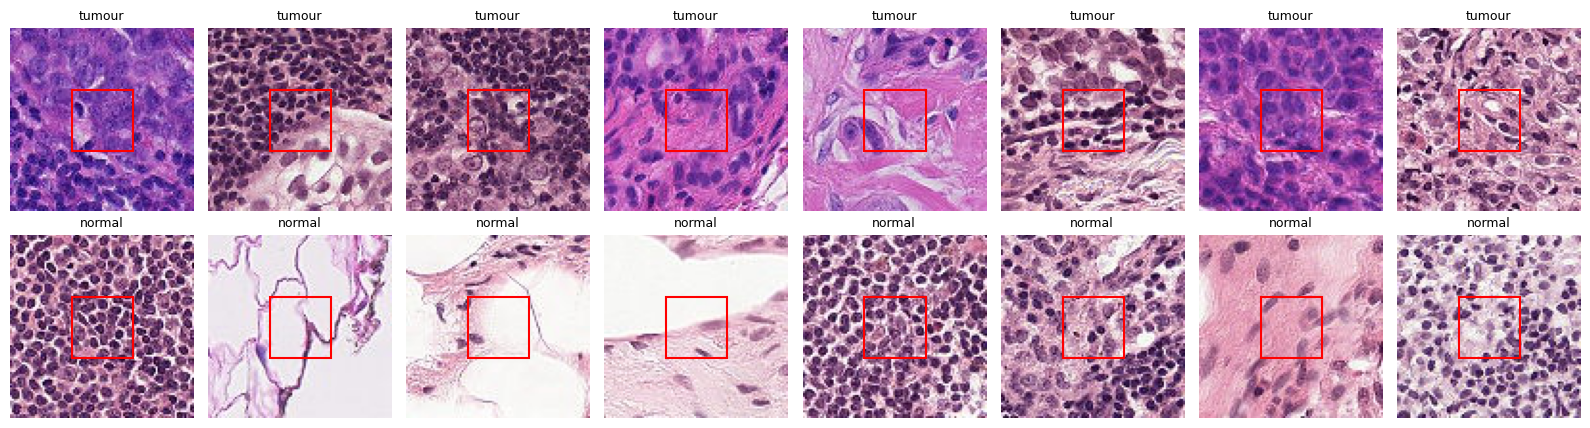

In [ ]:
x_train = np.load(f'{PCAM}/train_x.npy', mmap_mode = 'r')
y_train = labels['train']

fig, axes = plt.subplots(2, 8, figsize = (16, 4.4))
for row, lab in enumerate([1, 0]):
    idx = np.random.choice(np.flatnonzero(y_train == lab), 8, replace = False)
    for ax, i in zip(axes[row], idx):
        ax.imshow(x_train[i])
        ax.add_patch(plt.Rectangle((32, 32), 32, 32, fill = False, color = 'red', lw = 1.5))
        ax.set_title('tumour' if lab else 'normal', fontsize = 9)
        ax.axis('off')
plt.tight_layout()
plt.show()

## 5. Dataset and augmentation

**Dataset.** It only reads raw patches from the memory-mapped file. All augmentation happens on the GPU, because Colab has just 2 CPU cores and they would slow training down.

**Augmentation, done on the GPU for each image:**
1. **Rotation by 0/90/180/270° and a random flip.** A tissue section has no "up", so all 8 versions are valid. (On the chest X-ray we couldn't flip, because the heart is on the left. Here we can.)
2. **HED stain jitter.** H&E colours vary between labs. We convert the image to the amount of each stain (Haematoxylin, Eosin, DAB), multiply each by a random 0.95-1.05, shift it by a random ±0.05, and convert back. The model sees the same tissue stained slightly differently, so it learns shapes, not one lab's colours.

How the stain maths works: stains add up in **optical density** space, `OD = -log(pixel / 255)`, not in RGB. So we go RGB → OD → stains, change the stains, then go back.

In [ ]:
class PCamDataset(Dataset):
    def __init__(self, split, indices = None):
        self.x = np.load(f'{PCAM}/{split}_x.npy', mmap_mode = 'r')
        self.y = np.load(f'{PCAM}/{split}_y.npy')
        self.indices = np.arange(len(self.y)) if indices is None else indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        j = self.indices[i]
        img = np.array(self.x[j])                         # (96, 96, 3) uint8, copied out of the memory map
        return torch.from_numpy(img).permute(2, 0, 1), torch.tensor(float(self.y[j]))

In [ ]:
HED = torch.tensor(hed_from_rgb, dtype = torch.float32)
RGB = torch.tensor(rgb_from_hed, dtype = torch.float32)
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1) * 255     # imagenet statistics
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1) * 255


def gpu_augment(x, stain_aug = True, sigma = 0.05, bias = 0.05):
    # x: (B, 3, H, W) uint8 on the gpu -> float 0..255
    B = x.shape[0]
    x = x.float()
    # 1. random rotation (k * 90 degrees) and flip, different for each image
    k = torch.randint(0, 4, (B,), device = x.device)
    out = torch.empty_like(x)
    for r in range(4):
        idx = (k == r).nonzero(as_tuple = True)[0]
        if len(idx):
            out[idx] = torch.rot90(x[idx], r, dims = (2, 3))
    flip = torch.rand(B, device = x.device) < 0.5
    out[flip] = torch.flip(out[flip], dims = (3,))
    # 2. hed stain jitter
    if stain_aug:
        od = -torch.log((out + 1) / 256)                                         # rgb -> optical density
        hed = torch.einsum('bchw,cd->bdhw', od, HED.to(x.device))                # od -> stain amounts
        alpha = torch.empty(B, 3, 1, 1, device = x.device).uniform_(1 - sigma, 1 + sigma)
        beta = torch.empty(B, 3, 1, 1, device = x.device).uniform_(-bias, bias)
        od = torch.einsum('bdhw,dc->bchw', hed * alpha + beta, RGB.to(x.device))   # back to od
        out = (256 * torch.exp(-od) - 1).clamp(0, 255)                           # back to rgb
    return out


def normalize(x255):
    # pretrained imagenet models expect this normalization
    return (x255 - MEAN.to(x255.device)) / STD.to(x255.device)

Check that the augmentation looks right: same tissue, rotated, slightly different colour.

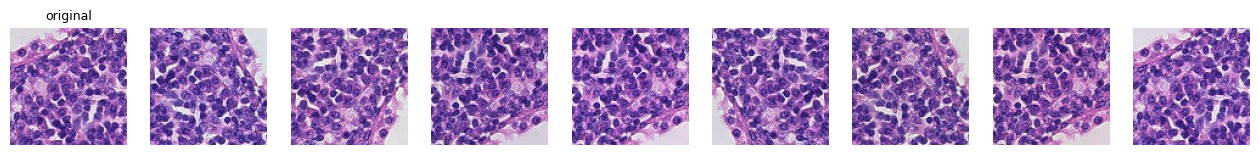

In [ ]:
sample = torch.from_numpy(np.array(x_train[:1])).permute(0, 3, 1, 2).repeat(8, 1, 1, 1)
aug = gpu_augment(sample.to(device), STAIN_AUG).cpu().byte().permute(0, 2, 3, 1).numpy()
fig, axes = plt.subplots(1, 9, figsize = (16, 2.2))
axes[0].imshow(x_train[0])
axes[0].set_title('original', fontsize = 9)
for ax, im in zip(axes[1:], aug):
    ax.imshow(im)
for ax in axes:
    ax.axis('off')
plt.show()

In [ ]:
indices = None
if TRAIN_FRACTION < 1:
    indices = np.random.default_rng(SEED).choice(len(y_train), int(len(y_train) * TRAIN_FRACTION), replace = False)
train_ds = PCamDataset('train', indices)
val_ds = PCamDataset('valid')
test_ds = PCamDataset('test')

kw = dict(num_workers = WORKERS, pin_memory = device.type == 'cuda')
train_dl = DataLoader(train_ds, batch_size = BATCH, shuffle = True, drop_last = True, **kw)
val_dl = DataLoader(val_ds, batch_size = BATCH * 2, shuffle = False, **kw)
test_dl = DataLoader(test_ds, batch_size = BATCH * 2, shuffle = False, **kw)
print('train', len(train_ds), '| val', len(val_ds), '| test', len(test_ds))

train 262144 | val 32768 | test 32768


## 6. Model

**Transfer learning.** We take a **ResNet-18** that was trained on ImageNet (1.2M everyday photos) and replace its last layer with one output: the tumour logit. Edges, textures and blobs learnt from photos are useful for tissue too. ResNet-18 (11M parameters) is fast and strong enough at 96 px.

`channels_last` is a memory layout that makes convolutions faster on the T4's tensor cores.

In [ ]:
def build_model(arch = 'resnet18', pretrained = True):
    if arch == 'resnet18':
        m = torchvision.models.resnet18(weights = 'IMAGENET1K_V1' if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, 1)
    elif arch == 'resnet50':
        m = torchvision.models.resnet50(weights = 'IMAGENET1K_V2' if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, 1)
    else:
        raise ValueError(arch)
    return m


model = build_model(ARCH, PRETRAINED).to(device).to(memory_format = torch.channels_last)
print(f'{sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 168MB/s]


11.2M parameters


## 7. Training

The recipe, each piece in plain words:
- **Loss:** `BCEWithLogitsLoss`, binary cross-entropy with the sigmoid built in (more stable numerically).
- **Optimizer:** AdamW, with no weight decay on biases and batch-norm weights (decaying those hurts).
- **Learning rate:** a short warm-up (first 5% of steps) so the first big gradients don't wreck the pretrained weights, then cosine decay to 0.
- **Mixed precision (fp16):** about 2× faster on a T4. `GradScaler` scales the loss up so small fp16 gradients don't round to zero.
- **Gradient clipping at 1.0:** protects against rare loss spikes.
- **Early stopping:** after every epoch, measure val AUC and keep the best model. Stop after `PATIENCE` epochs without improvement.

In [ ]:
def make_optimizer(model):
    decay = [p for n, p in model.named_parameters() if p.ndim > 1]
    no_decay = [p for n, p in model.named_parameters() if p.ndim <= 1]
    return torch.optim.AdamW([{'params': decay, 'weight_decay': WEIGHT_DECAY},
                              {'params': no_decay, 'weight_decay': 0.0}], lr = LR)


def warmup_cosine(optimizer, total_steps, warmup_frac = 0.05):
    warmup = max(1, int(total_steps * warmup_frac))
    def f(step):
        if step < warmup:
            return (step + 1) / warmup
        return 0.5 * (1 + np.cos(np.pi * min(1.0, (step - warmup) / max(1, total_steps - warmup))))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, f)

In [ ]:
use_amp = device.type == 'cuda'

def train_one_epoch(model, loader, optimizer, scheduler, scaler):
    model.train()
    loss_fn = nn.BCEWithLogitsLoss()
    total, n = 0.0, 0
    for step, (x, y) in enumerate(loader):
        if MAX_STEPS and step >= MAX_STEPS:
            break
        x = x.to(device, non_blocking = True)
        y = y.to(device, non_blocking = True)
        x = normalize(gpu_augment(x, STAIN_AUG)).contiguous(memory_format = torch.channels_last)
        with torch.autocast(device_type = device.type, dtype = torch.float16, enabled = use_amp):
            loss = loss_fn(model(x).squeeze(1).float(), y)
        optimizer.zero_grad(set_to_none = True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        total += loss.item() * len(y)
        n += len(y)
    return total / n


@torch.no_grad()
def predict(model, loader, tta = False):
    # returns probabilities and labels. tta = average over the 8 rotations / flips
    model.eval()
    probs, ys = [], []
    for x, y in loader:
        x = normalize(x.to(device).float()).contiguous(memory_format = torch.channels_last)
        with torch.autocast(device_type = device.type, dtype = torch.float16, enabled = use_amp):
            if tta:
                views = []
                for k in range(4):
                    xr = torch.rot90(x, k, dims = (2, 3))
                    views += [xr, torch.flip(xr, dims = (3,))]
                p = torch.stack([torch.sigmoid(model(v)).float() for v in views]).mean(0)
            else:
                p = torch.sigmoid(model(x)).float()
        probs.append(p.squeeze(1).cpu().numpy())
        ys.append(y.numpy())
    return np.concatenate(probs), np.concatenate(ys)

In [ ]:
optimizer = make_optimizer(model)
steps = len(train_dl) if not MAX_STEPS else min(len(train_dl), MAX_STEPS)
scheduler = warmup_cosine(optimizer, EPOCHS * steps)
scaler = torch.amp.GradScaler(device.type, enabled = use_amp)
config = {'arch': ARCH, 'tile': 96, 'downsample': 4.0, 'epochs': EPOCHS, 'lr': LR, 'stain_aug': STAIN_AUG}

history, best_auc, bad = [], -1, 0
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    train_loss = train_one_epoch(model, train_dl, optimizer, scheduler, scaler)
    pv, yv = predict(model, val_dl)
    val_auc = roc_auc_score(yv, pv)
    val_loss = float(nn.functional.binary_cross_entropy(torch.tensor(pv).clamp(1e-6, 1 - 1e-6), torch.tensor(yv)))
    history.append({'epoch': epoch, 'train_loss': train_loss, 'val_loss': val_loss, 'val_auc': val_auc,
                    'val_acc': float(((pv >= 0.5) == yv).mean()), 'minutes': (time.time() - t0) / 60})
    print({k: round(v, 4) for k, v in history[-1].items()})
    if val_auc > best_auc:
        best_auc, bad = val_auc, 0
        torch.save({'state_dict': model.state_dict(), 'config': config, 'epoch': epoch}, f'{RUN}/best.pt')
    else:
        bad += 1
        if bad >= PATIENCE:
            print('early stop')
            break
pd.DataFrame(history).to_csv(f'{RUN}/history.csv', index = False)
print('best val auc', round(best_auc, 4))

{'epoch': 1, 'train_loss': 0.2, 'val_loss': 0.3344, 'val_auc': np.float64(0.9454), 'val_acc': 0.8709, 'minutes': 2.9991}
{'epoch': 2, 'train_loss': 0.1196, 'val_loss': 0.3827, 'val_auc': np.float64(0.9493), 'val_acc': 0.8525, 'minutes': 2.4456}
{'epoch': 3, 'train_loss': 0.0966, 'val_loss': 0.403, 'val_auc': np.float64(0.9533), 'val_acc': 0.8679, 'minutes': 2.6922}
{'epoch': 4, 'train_loss': 0.0783, 'val_loss': 0.4016, 'val_auc': np.float64(0.958), 'val_acc': 0.8731, 'minutes': 2.7247}
{'epoch': 5, 'train_loss': 0.0629, 'val_loss': 0.3914, 'val_auc': np.float64(0.9609), 'val_acc': 0.8785, 'minutes': 2.7029}
{'epoch': 6, 'train_loss': 0.0552, 'val_loss': 0.4038, 'val_auc': np.float64(0.9605), 'val_acc': 0.8831, 'minutes': 2.7254}
best val auc 0.9609


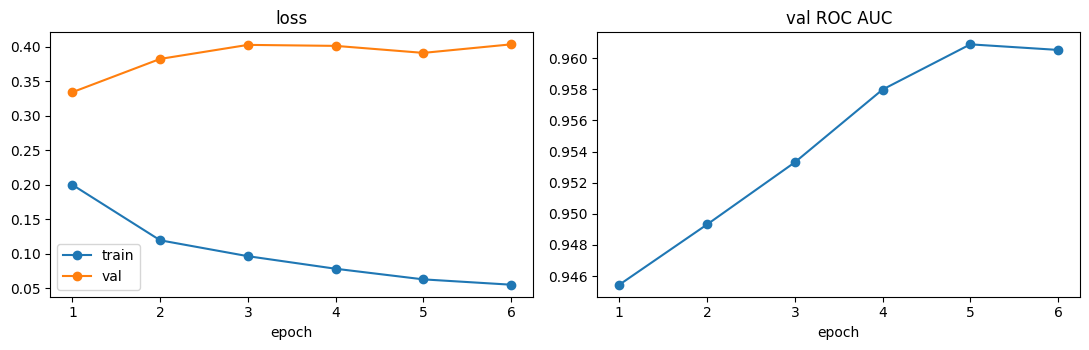

In [ ]:
h = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize = (11, 3.6))
axes[0].plot(h.epoch, h.train_loss, marker = 'o', label = 'train')
axes[0].plot(h.epoch, h.val_loss, marker = 'o', label = 'val')
axes[0].set_title('loss')
axes[0].legend()
axes[1].plot(h.epoch, h.val_auc, marker = 'o')
axes[1].set_title('val ROC AUC')
for ax in axes:
    ax.set_xlabel('epoch')
plt.tight_layout()
plt.savefig(f'{RUN}/figures/pcam_training_curves.png', dpi = 120)
plt.show()

## 8. Evaluation on the test set

Four rules for testing honestly:
1. **Load the best epoch**, not the last one.
2. **Choose the threshold on validation**, as the highest threshold that still catches 90% of tumour patches. Then apply it to test unchanged. Choosing it on test would be cheating.
3. **CI over slides, not patches.** The 32,768 test patches come from only a few dozen slides, and patches from one slide are correlated. So the bootstrap resamples whole slides. That gives an honest, wider CI.
4. **TTA (test-time augmentation):** average the prediction over the 8 rotations/flips. Report it next to the plain result, so you can judge whether 8× the compute is worth it.

In [ ]:
ckpt = torch.load(f'{RUN}/best.pt', map_location = device, weights_only = False)
model.load_state_dict(ckpt['state_dict'])
print('loaded epoch', ckpt['epoch'])


def threshold_for_recall(y, p, target):
    # sort the tumour scores high -> low; the k-th one is the highest threshold that keeps k tumours
    pos = np.sort(p[y == 1])[::-1]
    k = int(np.ceil(target * len(pos)))
    return float(pos[k - 1])


def report(y, p, thr):
    tn, fp, fn, tp = confusion_matrix(y, (p >= thr).astype(int), labels = [0, 1]).ravel()
    return {'threshold': round(thr, 4), 'auc': round(roc_auc_score(y, p), 4), 'accuracy': round((tp + tn) / len(y), 4),
            'recall': round(tp / (tp + fn), 4), 'precision': round(tp / max(tp + fp, 1), 4),
            'specificity': round(tn / (tn + fp), 4), 'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)}


def slide_bootstrap_auc(y, p, slides, n_boot = 1000, seed = 0):
    # resample whole slides with replacement, recompute auc each time
    rng = np.random.default_rng(seed)
    uniq, inv = np.unique(slides, return_inverse = True)
    members = [np.flatnonzero(inv == g) for g in range(len(uniq))]
    aucs = []
    for _ in range(n_boot):
        idx = np.concatenate([members[g] for g in rng.integers(0, len(uniq), len(uniq))])
        if len(np.unique(y[idx])) == 2:
            aucs.append(roc_auc_score(y[idx], p[idx]))
    return np.percentile(aucs, [2.5, 97.5]).round(4).tolist()

loaded epoch 5


In [ ]:
results = {}
for tta in [False, True]:
    name = 'tta' if tta else 'plain'
    pv, yv = predict(model, val_dl, tta)
    pt, yt = predict(model, test_dl, tta)
    thr = threshold_for_recall(yv, pv, TARGET_RECALL)
    results[name] = {'val_at_thr': report(yv, pv, thr), 'test_at_thr': report(yt, pt, thr),
                     'test_at_0.5': report(yt, pt, 0.5),
                     'test_auc_ci95_slides': slide_bootstrap_auc(yt, pt, meta['test']['wsi'].values, N_BOOT)}
    if not tta:
        p_test = pt
    print(f'[{name}] test AUC {results[name]["test_at_0.5"]["auc"]} (95% CI {results[name]["test_auc_ci95_slides"]}), '
          f'accuracy at 0.5 {results[name]["test_at_0.5"]["accuracy"]}')
    print(f'   threshold {thr:.3f}: val recall {results[name]["val_at_thr"]["recall"]} -> '
          f'test recall {results[name]["test_at_thr"]["recall"]}, precision {results[name]["test_at_thr"]["precision"]}')
y_test = yt

[plain] test AUC 0.9413 (95% CI [0.9176, 0.9615]), accuracy at 0.5 0.8276
   threshold 0.054: val recall 0.9001 -> test recall 0.8484, precision 0.8932
[tta] test AUC 0.9488 (95% CI [0.9256, 0.968]), accuracy at 0.5 0.8317
   threshold 0.114: val recall 0.9001 -> test recall 0.8342, precision 0.9258


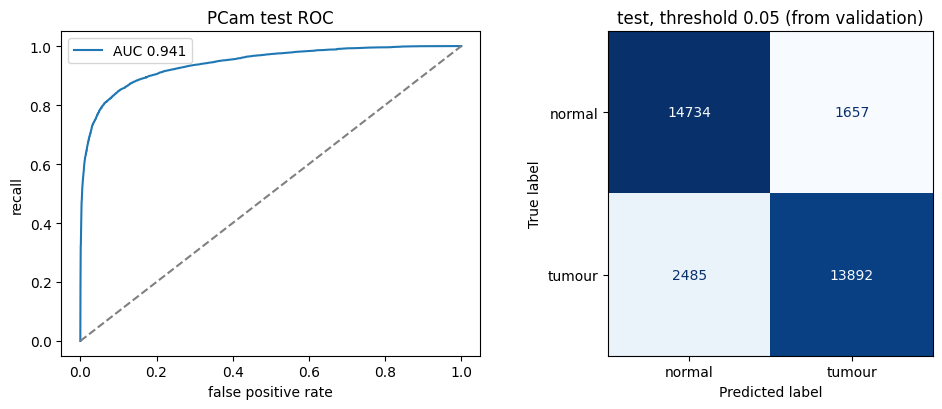

In [ ]:
json.dump({'results': results, 'split_report': split_report}, open(f'{RUN}/test_results.json', 'w'), indent = 2, default = int)
thr = results['plain']['val_at_thr']['threshold']

fig, axes = plt.subplots(1, 2, figsize = (10, 4.2))
fpr, tpr, _ = roc_curve(y_test, p_test)
axes[0].plot(fpr, tpr, label = f'AUC {results["plain"]["test_at_0.5"]["auc"]:.3f}')
axes[0].plot([0, 1], [0, 1], '--', color = 'grey')
axes[0].set_xlabel('false positive rate')
axes[0].set_ylabel('recall')
axes[0].set_title('PCam test ROC')
axes[0].legend()
ConfusionMatrixDisplay.from_predictions(y_test, (p_test >= thr).astype(int), display_labels = ['normal', 'tumour'],
                                        cmap = 'Blues', colorbar = False, ax = axes[1])
axes[1].set_title(f'test, threshold {thr:.2f} (from validation)')
plt.tight_layout()
plt.savefig(f'{RUN}/figures/pcam_roc_confusion.png', dpi = 120)
plt.show()

**The most confident mistakes.** Look at each one. Is the label plausibly wrong? Is the tumour only at the edge of the patch, outside the labelled centre? Is it blurry, folded tissue or a pen mark? These are your error-analysis talking points.

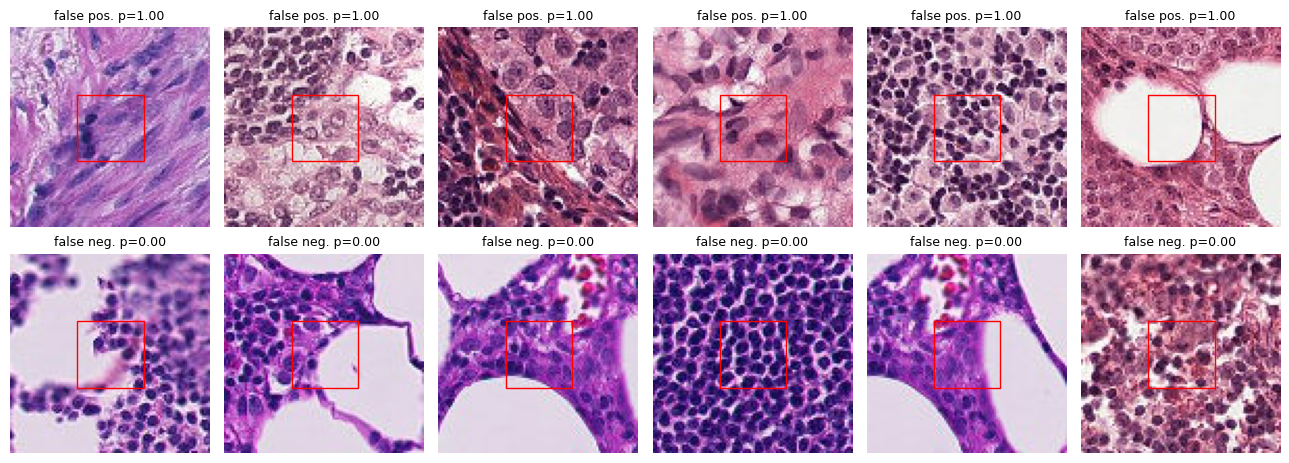

In [ ]:
x_test = np.load(f'{PCAM}/test_x.npy', mmap_mode = 'r')
fp_idx = np.argsort(-(p_test * (y_test == 0)))[:6]        # normal patches with the highest scores
fn_idx = np.argsort(p_test + 2 * (y_test == 0))[:6]       # tumour patches with the lowest scores
fig, axes = plt.subplots(2, 6, figsize = (13, 4.8))
for ax, i in zip(axes[0], fp_idx):
    ax.imshow(x_test[i])
    ax.set_title(f'false pos. p={p_test[i]:.2f}', fontsize = 9)
for ax, i in zip(axes[1], fn_idx):
    ax.imshow(x_test[i])
    ax.set_title(f'false neg. p={p_test[i]:.2f}', fontsize = 9)
for ax in axes.ravel():
    ax.add_patch(plt.Rectangle((32, 32), 32, 32, fill = False, color = 'red', lw = 1))
    ax.axis('off')
plt.tight_layout()
plt.savefig(f'{RUN}/figures/pcam_errors.png', dpi = 120)
plt.show()

In [ ]:
# which test slides are hardest?
m = meta['test'].copy()
m['y'], m['p'] = y_test, p_test
per_slide = m.groupby('wsi').apply(lambda g: pd.Series({'patches': len(g), 'tumour_share': g.y.mean(),
                                                         'accuracy': ((g.p >= 0.5) == g.y).mean()}), include_groups = False)
per_slide.sort_values('accuracy').round(3).head(8)

,patches,tumour_share,accuracy
wsi,,,
camelyon16_test_099,677.0,0.858,0.213
camelyon16_test_013,566.0,0.827,0.320
camelyon16_test_084,648.0,0.843,0.353
camelyon16_test_079,678.0,0.857,0.389
camelyon16_test_038,492.0,0.689,0.492
camelyon16_test_113,596.0,0.792,0.523
camelyon16_test_051,570.0,0.812,0.551
camelyon16_test_011,492.0,0.722,0.593


**Files for the Streamlit app:** the model with fp16 weights (half the size, same predictions to ~3 decimals) and a few example test tiles.

In [ ]:
APP = f'{OUT}/app_artifacts'
os.makedirs(f'{APP}/examples/pcam', exist_ok = True)
torch.save({'state_dict': {k: v.half() if v.is_floating_point() else v for k, v in model.state_dict().items()},
            'config': config}, f'{APP}/pcam_best.pt')
rng = np.random.default_rng(0)
for lab, tag in [(1, 'tumour'), (0, 'normal')]:
    for j, i in enumerate(rng.choice(np.flatnonzero(y_test == lab), 4, replace = False)):
        Image.fromarray(np.asarray(x_test[i])).save(f'{APP}/examples/pcam/{tag}_{j}.png')
print(os.listdir(APP), round(os.path.getsize(f'{APP}/pcam_best.pt') / 1e6, 1), 'MB')

['examples', 'pcam_best.pt'] 22.4 MB


## 9. Summary: write these into RESULTS.md

| What | Where it printed |
|---|---|
| shared slides train-valid / train-test / valid-test | section 3 |
| best epoch and val AUC | section 7 |
| test AUC + 95% CI (slides) | section 8, `[plain]` |
| threshold, val recall → test recall, precision | section 8 |
| TTA gain | `[tta]` vs `[plain]` |
| worst slides | last cell |

`best.pt` is in `MyDrive/patho/runs/pcam_resnet18/`. Part 2 loads it from there.